# Figures for EGU

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import datetime
from scipy.optimize import curve_fit


In [2]:
class data():
    def __init__(self,path,period,start_date, end_date,BG,bg_str,correlation='no',verification=False,verification_path=''):
        self.path = path
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.verification=verification
        self.color=''
        self.BG=BG
        self.bg_str=bg_str
        if verification:
            self.verification_path=verification_path
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/{self.period}_{self.bg_str}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/gosat_data_2x2_{self.period}_{self.bg_str}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/insitu_data_2x2_{self.period}_{self.bg_str}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()

In [3]:
footprint=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/RemoTeCv240/prep_footprints_CAMS/diurnal_amplitude_weekly/high_res_scaled_footprints_20201001-20220331_weekly.nc')

In [ ]:
for i in range(1000):#[75]:#[5,7,37,38,40,51,54,55,73,75]:
    fig,ax1=plt.subplots(1,1,figsize=(7,5), subplot_kw={'projection': ccrs.PlateCarree()})
    #fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(20,5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Footprint GOSAT {i}")
    temp=footprint.isel(pointspec=i).spec001_mr.sum(dim='time')*1e-6
    plot=temp.plot(ax=ax1, cmap='Reds', cbar_kwargs={'location':'bottom','label':r'Footprint [$\mathrm{\frac{s m^2}{mg}}$]','shrink':0.85,'aspect': 25,'pad':0.1})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)
    #ax1.set_xlabel('longitude')
    #ax1.set_ylabel('latitude')
    # Add coastlines
    ax1.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax1.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax1.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax1.grid(c='lightgrey')
    ax1.set_xlim(-134,-62) 
    ax1.set_ylim(12,56)
    ax1.set_title('')
    #ax1.tick_params(labelsize=100)
    plt.savefig(f'figures/EGU/footprints/frame_{i:03d}.png')
    #plt.savefig('figures/EGU/footprint_gosat.png',transparent=True)
    #plt.show()
    plt.close()

In [ ]:
footprint=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/Flexpart/insitu/prep_footprints_CAMS/diurnal_amplitude_weekly/high_res_scaled_footprints_20201001-20220331_weekly.nc')

In [ ]:
for i in range(1000):#[12]: # [2,5,11,12,14,16,32,35,37,38]:
    fig,ax1=plt.subplots(1,1,figsize=(7,5), subplot_kw={'projection': ccrs.PlateCarree()})
    #fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(20,5), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f"Footprint insitu {i}")
    temp=footprint.isel(pointspec=i).spec001_mr.sum(dim='time')*1e-6
    plot=temp.plot(ax=ax1, cmap='Reds', cbar_kwargs={'location':'bottom','label':'','shrink':0.85,'aspect': 25,'pad':0.1})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)
    ax1.set_xlabel('longitude')
    ax1.set_ylabel('latitude')
    # Add coastlines
    ax1.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax1.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax1.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax1.grid(c='lightgrey')
    ax1.set_xlim(-134,-62) 
    ax1.set_ylim(12,56)
    ax1.set_title('')
    ax1.tick_params(labelsize=20)
    plt.savefig(f'figures/EGU/footprints/frame_{i:03d}.png')
    #plt.savefig('figures/EGU/footprint_insitu.png',transparent=True)
    #plt.show()
    plt.close()


# Gosat and insitu measurement locations for one month

In [4]:
path='inversions_TM5'
period='20201001-20220331'
start_date, end_date =dt.date(2021,1,1), dt.date(2021,12,31) 
savefig='figures/correlation/' 
verification=True
verification_path=path+'/verification.json'
correlations=['no','with']
color=['red','blue','yellow','purple','gray']
gosat=xr.open_dataset(f'{path}/2x2/no_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/gosat_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
insitu=xr.open_dataset(f'{path}/2x2/no_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/insitu_data_2x2_{period}_RemoTeC_2.4.1+IS-land_ocean_bc_bg.nc')
BG='TM5'
bg_str='RemoTeC_2.4.1+IS-land_ocean_bc'
inversion_TM5={}
for i in range(len(correlations)):
    inversion_TM5[correlations[i]]=data(path,period,start_date, end_date,BG,bg_str,correlation=correlations[i],verification=verification)
    inversion_TM5[correlations[i]].read_data()
    inversion_TM5[correlations[i]].color=color[i]

In [ ]:
path='inversions_CAMS'
period='20201001-20220331'
start_date, end_date =dt.date(2021,1,1), dt.date(2021,12,31) 
savefig='figures/correlation/' 
verification=True
verification_path=path+'/verification.json'
correlations=['no','with']
color=['red','blue','yellow','purple','gray']
gosat=xr.open_dataset(f'{path}/2x2/no_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/gosat_data_2x2_{period}_satellite_bg.nc')
insitu=xr.open_dataset(f'{path}/2x2/no_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/insitu_data_2x2_{period}_satellite_bg.nc')
BG='CAMS'
bg_str='satellite'
inversion_CAMS={}
for i in range(len(correlations)):
    inversion_CAMS[correlations[i]]=data(path,period,start_date, end_date,BG,bg_str,correlation=correlations[i],verification=verification)
    inversion_CAMS[correlations[i]].read_data()
    inversion_CAMS[correlations[i]].color=color[i]

In [4]:
flexpart_region=[12,56,-134,-62]

analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

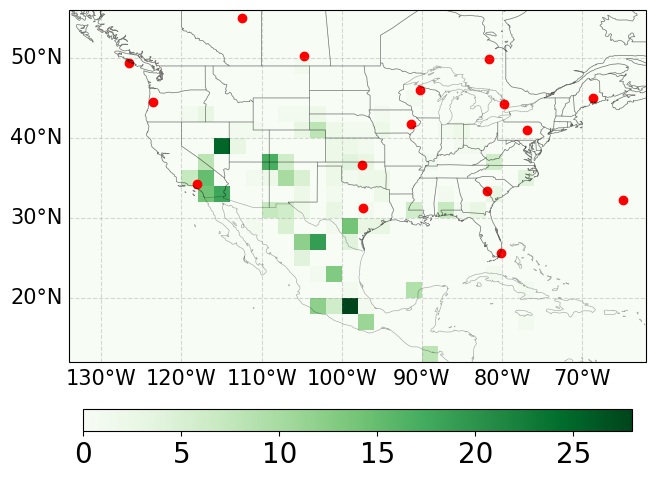

In [131]:
insitu_month=inversion_TM5['no'].insitu.where(inversion_TM5['no'].insitu.release_time.astype('datetime64[M]')==np.datetime64('2021-01'),drop=True)
gosat_month=inversion_TM5['no'].gosat.where(inversion_TM5['no'].gosat.release_time.astype('datetime64[M]')==np.datetime64('2021-01'),drop=True)

# Combine lat and lon into a pandas DataFrame
insitu_loc_df = pd.DataFrame({
    'lat': insitu_month['release_lat'].round(2).values,  # round to four nachkommastellen to neglect very small differences
    'lon': insitu_month['release_lon'].round(2).values,
})

# Drop duplicates to keep only unique locations
insitu_loc_df_unique = insitu_loc_df.drop_duplicates()

# Define the bin edges
lat_centers = np.arange(flexpart_region[0]+1, flexpart_region[1], 2)
lon_centers = np.arange(flexpart_region[2]+1, flexpart_region[3], 2)

# # Digitize the lat/lon into bins
# lat_idx = np.digitize(, lat_bins) - 1
# lon_idx = np.digitize(, lon_bins) - 1

# For each lat, find nearest lat_center
lat_idx = np.abs(gosat_month.release_lat.values[..., np.newaxis] - lat_centers).argmin(axis=-1)
lon_idx = np.abs(gosat_month.release_lon.values[..., np.newaxis] - lon_centers).argmin(axis=-1)

# count
counts = np.zeros((len(lat_centers), len(lon_centers)), dtype=int)

for i, j in zip(lat_idx.ravel(), lon_idx.ravel()):
    counts[i, j] += 1
        
fig, ax = plt.subplots(figsize=(7, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Grid for plotting
lon_grid, lat_grid = np.meshgrid(lon_centers, lat_centers)

mesh = ax.pcolormesh(lon_grid, lat_grid, counts, cmap='Greens', shading='auto')
cbar=plt.colorbar(mesh, ax=ax, location='bottom',shrink=0.85,aspect= 25,pad=0.1)
#cbar.set_label('Number of GOSAT measurements in January 2021', fontsize=15)
cbar.ax.tick_params(labelsize=20)
# plot insitu meas location
ax.scatter(insitu_loc_df_unique.lon, insitu_loc_df_unique.lat, color='r')

# Add coastlines
ax.coastlines(linewidth=0.5, alpha=0.3)
# Add U.S. state borders
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 15}
gl.ylabel_style = {'size': 15}
ax.grid(c='lightgrey')
ax.set_xlim(-134,-62)    # plot entire Flexpart region [12,56,-134,-62]
ax.set_ylim(12,56)
ax.tick_params(axis='both', labelsize=20)
fig.tight_layout()

plt.show()
fig.savefig('figures/EGU/meas_distribution.png',transparent=True,dpi=1000)

 Histogramm insitu gosat

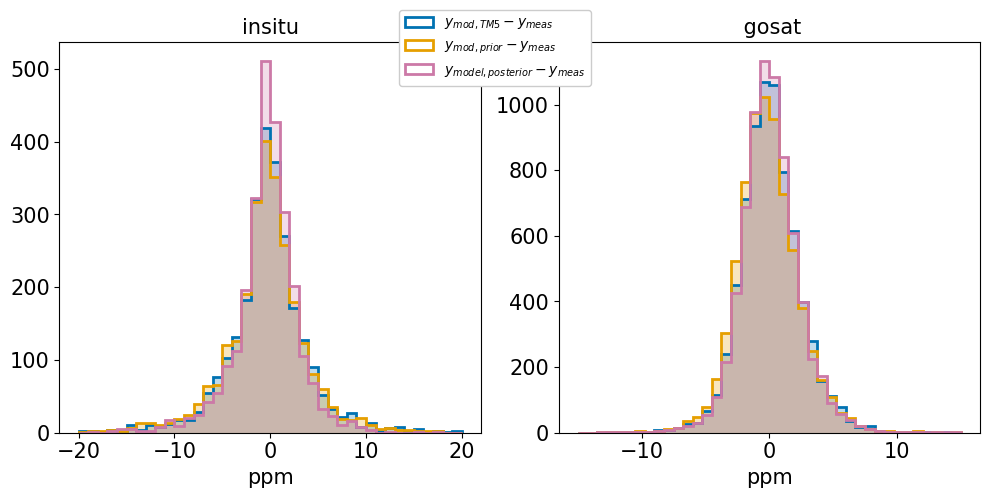

In [14]:
nbins=40
offset=[0,0.3,-0.3]
max_min=[(-20,20),(-20+offset[1],20+offset[1]),(-20+offset[2],20+offset[2])]
fig,axs=plt.subplots(1,2,figsize=(10,5))
max_min=(-20,20)
var=['ref_RemoteC_IS_diff','prior_diff','posterior_diff']
#color= ['lightgreen','orange','red']
#color = ['tab:blue', 'tab:orange', 'tab:green']
color = ['#0072B2', '#E69F00', '#CC79A7']
hatch = ['//','\\\\','..']
#color =  ['royalblue', 'darkorange', 'crimson']
label_0=['$y_{mod,TM5} -y_{meas}$','$y_{mod,prior} -y_{meas}$','$y_{model,posterior} -y_{meas}$']
temp=inversion_TM5['with'].insitu
for i in range(3):
    d0=np.round(np.mean(temp[var[i]]).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp[var[i]])).compute().item(),2)
    label=label=fr'{label_0[i]}' #, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    axs[0].hist(temp[var[i]], color=color[i],alpha=0.25, bins=nbins, range=max_min)
    axs[0].hist(temp[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min, label=label)
axs[0].set_xlabel('ppm',fontsize=15)
axs[0].set_title(f'insitu',fontsize=15)
axs[0].tick_params(axis='both', labelsize=15)

max_min=(-15,15)
temp=inversion_TM5['with'].gosat
for i in range(3):
    d0=np.round(np.mean(temp[var[i]]).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp[var[i]])).compute().item(),2)
    label=label=fr'{label_0[i]}'#, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    axs[1].hist(temp[var[i]], color=color[i],alpha=0.25, bins=nbins, range=max_min)
    axs[1].hist(temp[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min)
#axs[1].legend()
axs[1].set_xlabel('ppm',fontsize=15)
axs[1].set_title(f' gosat',fontsize=15)
axs[1].tick_params(axis='both', labelsize=15)
fig.legend(loc='upper center',bbox_to_anchor=(0.5, 1),framealpha=1)
fig.tight_layout()
plt.savefig(f'figures/EGU/histogramm_correlations.png',transparent=True,dpi=1000)

In [5]:
class data_full_period():
    def __init__(self,path,period,start_date, end_date,BG,BG_ds,correlation='no',verification=False,verification_path=''):
        self.path = path
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.verification=verification
        self.color=''
        self.BG=BG
        self.Bg_ds=BG_ds
        if verification:
            self.verification_path=verification_path
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/{self.period}_{BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/gosat_data_2x2_{period}_{BG_ds}_bg.nc')
    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/1ppm_gosat_meas_err/2ppm_insitu_meas_err/insitu_data_2x2_{period}_{BG_ds}_bg.nc')
    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()

In [6]:
path='inversions_TM5'
period='20201001-20220331'
start_date, end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
verification=True
savefig='figures/TM5/'
verification_path='verification.json'
correlations=['no', 'with', 'temporal', 'spatial', 'temporal_1M', 'with_1M', 'with_e04']
color=['red','blue','yellow','purple','gray','orange', 'green']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
inversion_TM5_full_period={}
for i in range(len(correlations)):
    inversion_TM5_full_period[correlations[i]]=data_full_period(path,period,start_date, end_date,BG,BG_ds,correlation=correlations[i],verification=verification,verification_path=verification_path)
    inversion_TM5_full_period[correlations[i]].read_data()
    inversion_TM5_full_period[correlations[i]].color=color[i]

In [7]:
with open(inversion_TM5_full_period['no'].path+'/'+inversion_TM5_full_period['no'].verification_path, 'r', encoding='utf-8') as file:
    data = json.load(file)

In [12]:

analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

In [9]:
temp_insitu

<xarray.Dataset> Size: 339kB
Dimensions:                                              (pointspec: 2496)
Coordinates:
  * pointspec                                            (pointspec) int64 20kB ...
    height                                               float32 4B 30.0
Data variables: (12/16)
    release_time                                         (pointspec) datetime64[ns] 20kB ...
    release_lat                                          (pointspec) float64 20kB ...
    release_lon                                          (pointspec) float64 20kB ...
    co2_val[ppm]                                         (pointspec) float64 20kB ...
    TM5_RemoTeC_2.4.1+IS-land_ocean_bc_background        (pointspec) float64 20kB ...
    TM5_RemoTeC_2.4.1+IS-land_ocean_bc_co2               (pointspec) float64 20kB ...
    ...                                                   ...
    ref_RemoteC_IS_val                                   (pointspec) float64 20kB ...
    TM5_molefrac_diff                                    (pointspec) float64 20kB ...
    TM5_molefrac_diff_interpolated                       (pointspec) float64 20kB ...
    prior_diff                                           (pointspec) float64 20kB ...
    posterior_diff                                       (pointspec) float64 20kB ...
    ref_RemoteC_IS_diff                                  (pointspec) float64 20kB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    ffadcb5 Fri Sep 19 15:51:15 2025 +0000
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-02-21 18:10 +0100  created by b383736 on l40...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          0
    sfc_only:               0
    linit_cond:             0

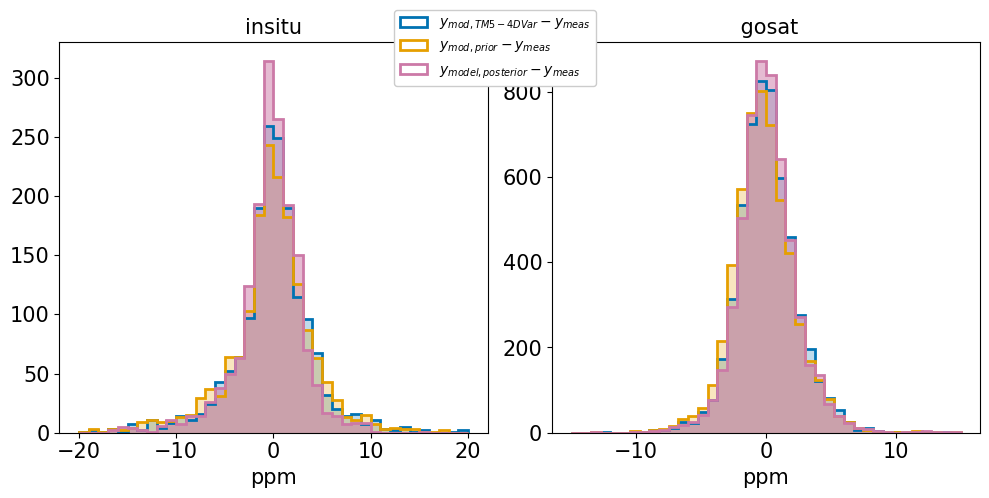

In [9]:
temp_insitu=inversion_TM5_full_period['with'].insitu.isel(pointspec=data['dataset_indizes_insitu'])
temp_insitu=temp_insitu.where((temp_insitu.release_time>=pd.to_datetime(start_date))&(temp_insitu.release_time<=pd.to_datetime(end_date)),drop=True)
temp_insitu=temp_insitu.where(((temp_insitu.release_lat>= analy_region_lat[0]) &(temp_insitu.release_lat<analy_region_lat[1])),drop=True)
temp_insitu=temp_insitu.where(((temp_insitu.release_lon>= analy_region_lon[0]) &(temp_insitu.release_lon<analy_region_lon[1])),drop=True)

temp_gosat=inversion_TM5_full_period['with'].gosat.isel(pointspec=data['dataset_indizes_gosat'])
temp_gosat=temp_gosat.where((temp_gosat.release_time>=pd.to_datetime(start_date))&(temp_gosat.release_time<=pd.to_datetime(end_date)),drop=True)
temp_gosat=temp_gosat.where(((temp_gosat.release_lat>= analy_region_lat[0]) &(temp_gosat.release_lat<analy_region_lat[1])),drop=True)
temp_gosat=temp_gosat.where(((temp_gosat.release_lon>= analy_region_lon[0]) &(temp_gosat.release_lon<analy_region_lon[1])),drop=True)

nbins=40
offset=[0,0.3,-0.3]
max_min=[(-20,20),(-20+offset[1],20+offset[1]),(-20+offset[2],20+offset[2])]
fig,axs=plt.subplots(1,2,figsize=(10,5))
max_min=(-20,20)
var=['ref_RemoteC_IS_diff','prior_diff','posterior_diff']
#color= ['lightgreen','orange','red']
#color = ['tab:blue', 'tab:orange', 'tab:green']
color = ['#0072B2', '#E69F00', '#CC79A7']
hatch = ['//','\\\\','..']
#color =  ['royalblue', 'darkorange', 'crimson']
label_0=['$y_{mod,TM5-4DVar} -y_{meas}$','$y_{mod,prior} -y_{meas}$','$y_{model,posterior} -y_{meas}$']
alpha=[0.25,0.25,0.5]
for i in range(3):
    d0=np.round(np.mean(temp_insitu[var[i]]).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp_insitu[var[i]])).compute().item(),2)
    label=label=fr'{label_0[i]}' #, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    axs[0].hist(temp_insitu[var[i]], color=color[i],alpha=alpha[i], bins=nbins, range=max_min)
    axs[0].hist(temp_insitu[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min, label=label)
axs[0].set_xlabel('ppm',fontsize=15)
axs[0].set_title(f'insitu',fontsize=15)
axs[0].tick_params(axis='both', labelsize=15)

max_min=(-15,15)
for i in range(3):
    d0=np.round(np.mean(temp_gosat[var[i]]).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp_gosat[var[i]])).compute().item(),2)
    label=label=fr'{label_0[i]}'#, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    axs[1].hist(temp_gosat[var[i]], color=color[i],alpha=alpha[i], bins=nbins, range=max_min)
    axs[1].hist(temp_gosat[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min)
#axs[1].legend()
axs[1].set_xlabel('ppm',fontsize=15)
axs[1].set_title(f' gosat',fontsize=15)
axs[1].tick_params(axis='both', labelsize=15)
fig.legend(loc='upper center',bbox_to_anchor=(0.5, 1),framealpha=1)
fig.tight_layout()
plt.savefig(f'figures/EGU/histogramm_correlations_inversion_set.png',transparent=True,dpi=1000)

In [21]:
data.keys()

dict_keys(['verification_indizes_gosat', 'dataset_indizes_gosat', 'verification_indizes_insitu', 'dataset_indizes_insitu'])

In [ ]:
def gauss(x, H, A, x0, sigma):
    return np.exp(-(x - x0)**2 / (2 * sigma**2))

In [12]:
from scipy.stats import norm

In [ ]:
curve_fit(temp_insitu[var[i]])

in-situ ref_RemoteC_IS_diff mu = 0.091, std = 4.586, |d| = 3.008, RMSE = 4.586
in-situ prior_diff mu = -0.486, std = 4.459, |d| = 3.121, RMSE = 4.459
in-situ posterior_diff mu = -0.223, std = 3.916, |d| = 2.841, RMSE = 3.916
GOSAT ref_RemoteC_IS_diff mu = 0.203, std = 2.148, |d| = 1.644, RMSE = 2.148
GOSAT prior_diff mu = 0.02, std = 2.243, |d| = 1.685, RMSE = 2.243
GOSAT posterior_diff mu = 0.181, std = 2.114, |d| = 1.628, RMSE = 2.114


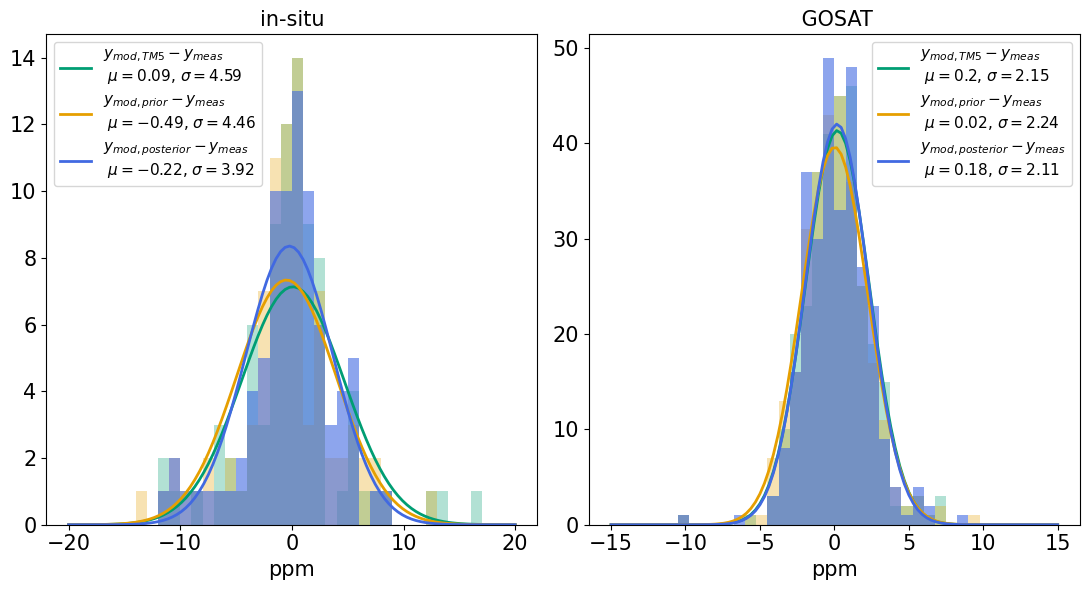

In [26]:
temp_insitu=inversion_TM5_full_period['with'].insitu.isel(pointspec=data['verification_indizes_insitu'])
temp_insitu=temp_insitu.where((temp_insitu.release_time>=pd.to_datetime(start_date))&(temp_insitu.release_time<=pd.to_datetime(end_date)),drop=True)
temp_insitu=temp_insitu.where(((temp_insitu.release_lat>= analy_region_lat[0]) &(temp_insitu.release_lat<analy_region_lat[1])),drop=True)
temp_insitu=temp_insitu.where(((temp_insitu.release_lon>= analy_region_lon[0]) &(temp_insitu.release_lon<analy_region_lon[1])),drop=True)

temp_gosat=inversion_TM5_full_period['with'].gosat.isel(pointspec=data['verification_indizes_gosat'])
temp_gosat=temp_gosat.where((temp_gosat.release_time>=pd.to_datetime(start_date))&(temp_gosat.release_time<=pd.to_datetime(end_date)),drop=True)
temp_gosat=temp_gosat.where(((temp_gosat.release_lat>= analy_region_lat[0]) &(temp_gosat.release_lat<analy_region_lat[1])),drop=True)
temp_gosat=temp_gosat.where(((temp_gosat.release_lon>= analy_region_lon[0]) &(temp_gosat.release_lon<analy_region_lon[1])),drop=True)


nbins=40
offset=[0,0.3,-0.3]
fig,axs=plt.subplots(1,2,figsize=(11,6))
max_min=(-20,20)
var=['ref_RemoteC_IS_diff','prior_diff','posterior_diff']
#color= ['green','orange','blue']
#color = ['tab:blue', 'tab:orange', 'tab:green']
#color = ['#0072B2', '#E69F00', '#CC79A7']
color = ['#377eb8', '#ff7f00', '#4daf4a', '#f781bf', '#a65628', '#984ea3', '#999999', '#e41a1c', '#dede00']
hatch = ['//','\\\\','..']
#color =  ['royalblue', 'darkorange', 'crimson']
color=['#009E73', '#E69F00', 'royalblue',]

label_0=['$y_{mod,TM5} -y_{meas}$','$y_{mod,prior} -y_{meas}$','$y_{mod,posterior} -y_{meas}$']
alpha=[0.3,0.3,0.6]
for i in range(3):    
    label=label=fr'{label_0[i]}' #, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    counts, bins, _ =axs[0].hist(temp_insitu[var[i]], color=color[i],alpha=alpha[i], bins=nbins, range=max_min)
    #axs[0].hist(temp_insitu[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min, label=label)

    x = np.linspace(max_min[0], max_min[1], 100)
    mu, std = norm.fit(temp_insitu[var[i]])
    RMSE=np.round(np.sqrt(sum((mu-temp_insitu[var[i]].values)**2)/len(temp_insitu[var[i]].values)),3)
    print(f'in-situ {var[i]} mu = {np.round(mu,3)}, std = {np.round(std,3)}, |d| = {np.round(np.mean(np.abs(temp_insitu[var[i]])).compute().item(),3)}, RMSE = {RMSE}')
    p = norm.pdf(x,mu, std)* len(temp_insitu[var[i]]) * (bins[1] - bins[0])
    label=label=fr'{label_0[i]}'+'\n'+fr' $\mu= {round(mu,2)}$, $\sigma={round(std,2)}$'
    axs[0].plot(x, p, color=color[i], linewidth=2, label=label)
axs[0].set_xlabel('ppm',fontsize=15)
axs[0].set_title(f'in-situ',fontsize=15)
axs[0].tick_params(axis='both', labelsize=15)
axs[0].legend(loc='upper left',fontsize=11)
max_min=(-15,15)
for i in range(3):
    #, $\overline{{d}}={d0}, \overline{{|d|}}={d_abs}$'
    counts, bins, _ =axs[1].hist(temp_gosat[var[i]], color=color[i],alpha=alpha[i], bins=nbins, range=max_min)
    #axs[1].hist(temp_gosat[var[i]], color=color[i], histtype='step', linewidth=2, bins=nbins, range=max_min)
    x = np.linspace(max_min[0], max_min[1], 100)
    mu, std = norm.fit(temp_gosat[var[i]])
    RMSE=np.round(np.sqrt(sum((mu-temp_gosat[var[i]].values)**2)/len(temp_gosat[var[i]].values)),3)
    print(f'GOSAT {var[i]} mu = {round(mu,3)}, std = {round(std,3)}, |d| = {np.round(np.mean(np.abs(temp_gosat[var[i]])).compute().item(),3)}, RMSE = {RMSE}')
    p = norm.pdf(x,mu, std)* len(temp_gosat[var[i]]) * (bins[1] - bins[0])
    label=label=fr'{label_0[i]}'+'\n'+fr' $\mu= {round(mu,2)}$, $\sigma={round(std,2)}$'
    axs[1].plot(x, p, color=color[i], linewidth=2, label=label)

#axs[1].legend()
axs[1].set_xlabel('ppm',fontsize=15)
axs[1].set_title(f' GOSAT',fontsize=15)
axs[1].tick_params(axis='both', labelsize=15)
#axs[1].legend(loc='upper right',bbox_to_anchor=(1.5, 1),handleheight=0.5)handletextpad
axs[1].legend(loc='upper right',fontsize=11)
fig.tight_layout()
plt.savefig(f'figures/EGU/histogramm_correlations_independent_samples.png',transparent=True,dpi=1000)


Divide analysis regions into 6 subregions

In [13]:
# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=int((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)
        

Overall Plot of Fluxes in that year that shows subregions

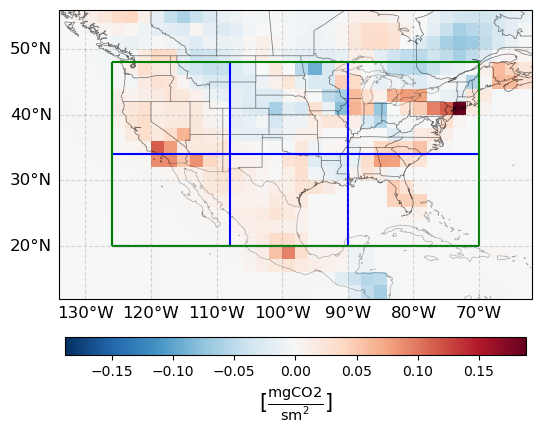

In [6]:
fig,ax1=plt.subplots(1,1,figsize=(7,5), subplot_kw={'projection': ccrs.PlateCarree()})
#fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(20,5), subplot_kw={'projection': ccrs.PlateCarree()})

temp=((inversion_TM5['with'].fluxes.TM5_posterior_flux)*1e6).mean(['time'])
plot=temp.plot(ax=ax1, cmap='RdBu_r', cbar_kwargs={'location':'bottom', 'label':r'[$\mathrm{\frac{mgCO2}{s m^2}}$]','shrink':0.85,'aspect': 25,'pad':0.1})
plot.colorbar.ax.xaxis.label.set_size(15)
plot.colorbar.ax.tick_params(labelsize=10)
#ax1.scatter([lon1,lon2],[lat1,lat2],color='purple', marker='*')
#ax1.scatter(stations1[0],stations1[1],color='green', marker='.')
#ax1.scatter(stations2[0],stations2[1],color='green', marker='.')

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        ax1.hlines(regions_lat[i],regions_lon[j], regions_lon[j+1],color='b')
        ax1.vlines(regions_lon[j],regions_lat[i],regions_lat[i+1],color='b')

ax1.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
ax1.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
ax1.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
ax1.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')

ax1.set_xlabel('longitude')
ax1.set_ylabel('latitude')
# Add coastlines
ax1.coastlines(linewidth=0.5, alpha=0.3)
# Add U.S. state borders
ax1.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
gl = ax1.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
ax1.grid(c='lightgrey')
ax1.set_xlim(-134,-62) 
ax1.set_ylim(12,56)
ax1.set_title('')
ax1.tick_params(labelsize=20)
plt.savefig(f'figures/EGU/regions+fluxes_sum_time_with.png',transparent=True,dpi=1500)

# Zeitreihe

In [9]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_1x1_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time.dt.date>=start_date)&(TM54DVar_posterior_flux.time.dt.date<=end_date),drop=True)

no correlation vs correlation

In [7]:
color = [
    '#D55E00',  #  vermillion (pops more than orange)
    '#0072B2',  #  strong blue (very high contrast)
    '#E69F00',  # orange (existing)
    '#009E73',  # green (existing)
    '#CC79A7',  #  magenta/purple (VERY eye-catching)
]
color=['#D55E00', 'royalblue', '#E69F00','#009E73','blueviolet']
color=['crimson', 'royalblue', '#E69F00','#009E73','deeppink']


In [12]:

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print([i,j])
        k=0
        for corr in ['no','with']:
            temp=inversion_TM5[corr].fluxes.where(((inversion_TM5[corr].fluxes.latitude>= regions_lat[i]) &(inversion_TM5[corr].fluxes.latitude<regions_lat[i+1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
                      
            plt.plot(temp.time, temp.TM5_posterior_flux, c=color[k], marker='o', markersize=2, linewidth=1.5, label=f'posterior {corr} correlation (TM5-4DVar BG) ')
            plt.fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=color[k], alpha=0.2)  
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[i]) &(TM54DVar_posterior_flux.latitude<regions_lat[i+1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        #temp3['prior_uncertainty']=temp3.prior_uncertainty*1e6
        plt.plot(temp.time, temp.TM5_prior_flux, c=color[2], marker='o',linewidth=0.9, markersize=1.5, label='prior')
        plt.fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color=color[2], alpha=0.15) 

        plt.plot(temp3.time, temp3.total_flux, c=color[3], marker='o',linewidth=0.9, markersize=1.5, label='TM5-4DVar flux')
        #plt.fill_between(temp3.time, temp3.TM5_posterior_flux-temp2.TM5_posterior_std, temp2.TM5_posterior_flux+temp2.TM5_posterior_std, color='red', alpha=0.2) 
        plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        plt.legend()
        plt.xticks(rotation=45)
        plt.tick_params(labelsize=10)

        plt.title(f"{regions_lat[i]} to {regions_lat[i+1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        plt.tight_layout()
        plt.ylim((-0.2,0.2))

        plt.savefig(f'figures/EGU/fluxes{regions_lat[i]}-{regions_lat[i+1]}N_{regions_lon[j]}-{regions_lon[j+1]}E.png',transparent=True,bbox_inches='tight',dpi=1000)
        plt.close()

<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_348776/4286645032.py:28: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


[0, 0]
[0, 1]
[0, 2]
[1, 0]
[1, 1]
[1, 2]


In [66]:

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print([i,j])
        
        temp=inversion_CAMS['with'].fluxes.where(((inversion_CAMS['with'].fluxes.latitude>= regions_lat[i]) &(inversion_CAMS['with'].fluxes.latitude<regions_lat[i+1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6             
        plt.plot(temp.time, temp.TM5_posterior_flux, c=color[4], marker='o', markersize=2, linewidth=1.5, label=f'posterior with CAMS background')
        plt.fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=color[4], alpha=0.2)  

        temp=inversion_TM5['with'].fluxes.where(((inversion_TM5['with'].fluxes.latitude>= regions_lat[i]) &(inversion_TM5['with'].fluxes.latitude<regions_lat[i+1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6             
        plt.plot(temp.time, temp.TM5_posterior_flux, c=color[1], marker='o', markersize=2, linewidth=1.5, label=f'posterior with TM5-4DVar background')
        plt.fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=color[1], alpha=0.2)  


        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[i]) &(TM54DVar_posterior_flux.latitude<regions_lat[i+1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        #temp3['prior_uncertainty']=temp3.prior_uncertainty*1e6
        plt.plot(temp.time, temp.TM5_prior_flux, c=color[2], marker='o', markersize=1.5, linewidth=0.9, label='prior')
        plt.fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color=color[2], alpha=0.2) 

        plt.plot(temp3.time, temp3.total_flux, c=color[3], marker='o', markersize=1.5,  linewidth=0.9, label='TM5-4DVar flux')
        #plt.fill_between(temp3.time, temp3.TM5_posterior_flux-temp2.TM5_posterior_std, temp2.TM5_posterior_flux+temp2.TM5_posterior_std, color='red', alpha=0.2) 
        plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        plt.legend()
        plt.xticks(rotation=45)
        plt.tick_params(labelsize=10)
        plt.title(f"{regions_lat[i]} to {regions_lat[i+1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        plt.tight_layout()
        plt.ylim((-0.2,0.2))
        plt.savefig(f'figures/EGU/camsvsTM5_fluxes{regions_lat[i]}-{regions_lat[i+1]}N_{regions_lon[j]}-{regions_lon[j+1]}E.png',bbox_inches='tight',transparent=True,dpi=500)
        plt.close()

<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_600486/2632078577.py:36: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


[0, 0]
[0, 1]
[0, 2]
[1, 0]
[1, 1]
[1, 2]


In [5]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom', 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(15)
    plot.colorbar.ax.tick_params(labelsize=15)

        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 12}
    gl.ylabel_style = {'size': 12}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [15]:
inversion=inversion_TM5
for k,week in enumerate(inversion['with'].fluxes.time.values):
    
    fig,(ax1,ax2)=plt.subplots(1,2,figsize=(16,6), subplot_kw={'projection': ccrs.PlateCarree()})
    
    fig.suptitle(f"Week of the {str(np.datetime64(week,'D'))}")
    temp=(inversion['no'].fluxes.TM5_posterior_flux).sel(time=week)*1e6
    plot_map(temp,r'posterior without correlation [$\mathrm{\frac{mgCO2}{s m^2}}$]',ax1)

    temp=(inversion['with'].fluxes.TM5_posterior_flux).sel(time=week)*1e6
    plot_map(temp,f'posterior with correlation'+r' [$\mathrm{\frac{mgCO2}{s m^2}}$]',ax2)
    plt.savefig(f'figures/EGU/frames/frame_{k:03d}.png')
    #plt.show()
    plt.close()


# Diurnal Cycle

In [3]:
nee=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/high_res_total_scaling_RemoTeC+IS.nc')

In [4]:
flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/weekly_mean_prior_scaling_RemoTeC+IS.nc')

In [5]:
for i in pd.date_range(start="2020-08-17",end="2020-08-31"):
    temp=flux.sel(latitude=28.5).sel(longitude=-111.5)
    temp=temp.where(temp.date<=i, drop=True)
    temp=temp.isel(date=-1)
    temp['date']=i
    if i==pd.to_datetime('2020-08-17'):
        daily=temp
    else:
        daily=xr.concat([daily,temp],'date')
    

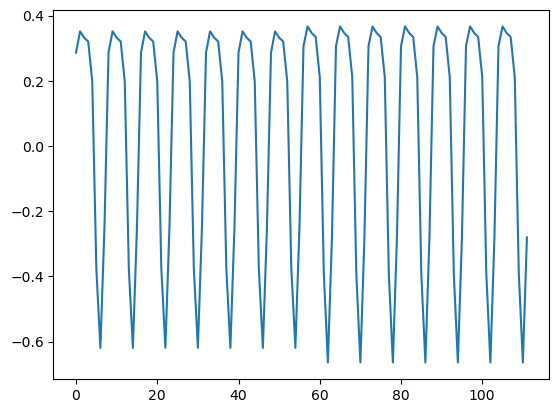

In [20]:
plt.plot(daily.nee.values.flatten()[:7*8*2])

gC/m^2/day-->kgCO2/m^2/s

In [10]:
flux['nee']=flux.nee*44/12*1e-3/(24*60*60)

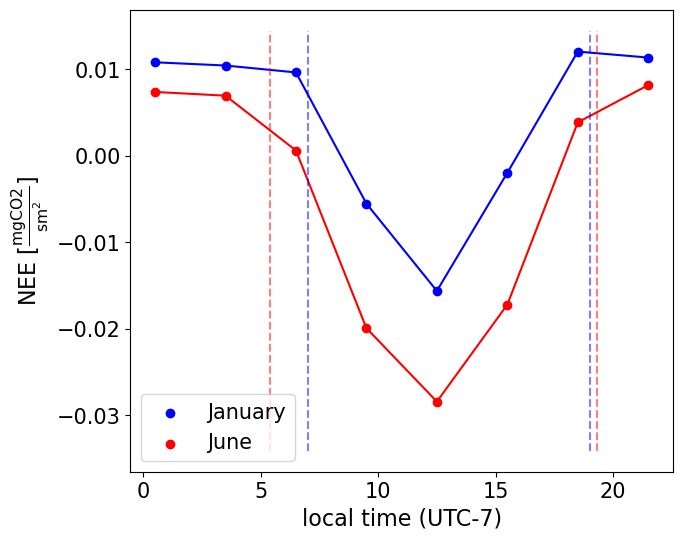

In [25]:
plt.figure(figsize=(7, 6))
temp1=flux.sel(latitude=28.5).sel(longitude=-111.5).sel(date=pd.to_datetime('2021-01-18'))
temp1['local_time']=temp1.time-7
for i in range(len(temp1.time.values)):
    if temp1.local_time[i]<0:
        temp1.local_time[i]=temp1.local_time[i]+24
temp1 = temp1.sortby("local_time")

plt.scatter(temp1.local_time.values,temp1.nee.values*1e6,color='b',label='January')
plt.plot(temp1.local_time.values,temp1.nee.values*1e6,color='b')

temp2=flux.sel(latitude=28.5).sel(longitude=-111.5).sel(date=pd.to_datetime('2021-06-07'))
temp2['local_time']=temp2.time-7
for i in range(len(temp2.time.values)):
    if temp2.local_time[i]<0:
        temp2.local_time[i]=temp2.local_time[i]+24
temp2 = temp2.sortby("local_time")
plt.scatter(temp2.local_time.values,temp2.nee.values*1e6,color='r',label='June')
plt.plot(temp2.local_time.values,temp2.nee.values*1e6,color='r')

max=np.max([temp1.nee.values*1e6,temp2.nee.values*1e6])
min=np.min([temp1.nee.values*1e6,temp2.nee.values*1e6])


plt.vlines(7,min*1.2,max*1.2, color='b',linestyle='dashed',alpha=0.5)
plt.vlines(19,min*1.2,max*1.2, color='b',linestyle='dashed',alpha=0.5)

plt.vlines(5.4,min*1.2,max*1.2, color='r',linestyle='dashed',alpha=0.5)
plt.vlines(19.3,min*1.2,max*1.2, color='r',linestyle='dashed',alpha=0.5)

plt.ylabel(r'NEE [$\mathrm{\frac{mgCO2}{s m^2}}$]',fontsize=16)
plt.xlabel('local time (UTC-7)',fontsize=16)
plt.tick_params(labelsize=15)
plt.legend(fontsize=15)
plt.savefig('figures/EGU/daily_cycle.svg',bbox_inches="tight",transparent=True)


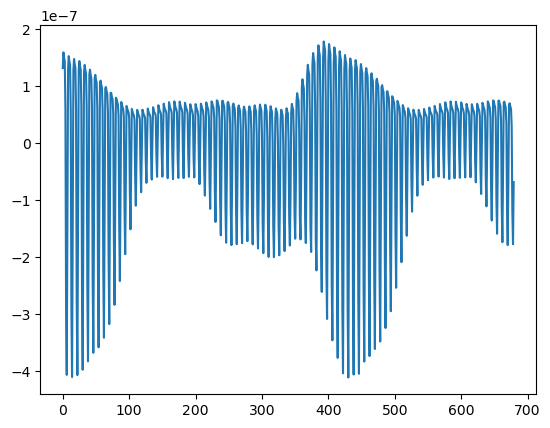

In [23]:
plt.plot(flux.sel(latitude=28.5).sel(longitude=-110.5).nee.values.flatten())

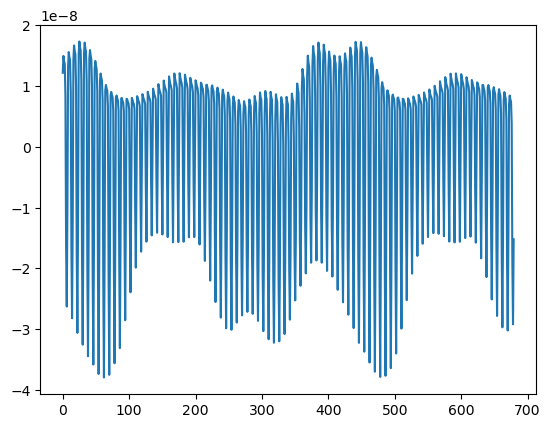

In [24]:
plt.plot(flux.sel(latitude=28.5).sel(longitude=-111.5).nee.values.flatten())